In [1]:
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
sys.path.append("../code")
import helpers

warnings.filterwarnings("ignore", message="covariance of constraints does not have full rank")
df, tax_sample, sa_sample = helpers.load_model_samples()
OUT = helpers.results_dir("missing_sa")

# Target: 1 if the SA rate is hidden or blank, 0 if reported (communes of the tax sample)
data = tax_sample.copy()
data["hidden"] = data["sa_rate"].isna().astype(int)

# Features: the model variables (as in notebook 05) plus tax per resident, which is known
# for every commune. Canton dummies are a separate block (some cantons hide more often)
X = helpers.ml_features(data).assign(log_tax=data["log_tax"])
X_canton = pd.concat([X, pd.get_dummies(data["canton"], prefix="canton", drop_first=True, dtype=float)], axis=1)
y = data["hidden"]
print(f"Communes: {len(data)} | SA hidden or blank: {y.sum()} ({y.mean():.1%})")
print(data["sa_status"].value_counts())

# How different are the hidden communes? Means by group
compare = ["population", "foreign_share", "share_under20", "share_65plus", "density",
           "jobs_per_capita", "tax_per_capita"]
table_groups = data.groupby("hidden")[compare].mean().T.rename(columns={0: "SA reported", 1: "SA hidden"})
table_groups["median, reported"] = data.loc[y == 0, compare].median()
table_groups["median, hidden"] = data.loc[y == 1, compare].median()
table_groups.index = [helpers.LABELS[c] for c in compare]
table_groups.to_csv(OUT / "table_reported_vs_hidden.csv")
table_groups.round(1)

Communes: 2108 | SA hidden or blank: 483 (22.9%)
sa_status
reported                  1625
secret                     353
blank                      124
partly hidden (merger)       6
Name: count, dtype: int64


hidden,SA reported,SA hidden,"median, reported","median, hidden"
Population,5198.6,759.8,2506.0,511.0
Foreign residents (% of population),19.4,12.4,17.9,11.1
Residents under 20 (%),20.6,19.5,20.6,20.0
Residents aged 65+ (%),19.8,21.6,19.6,20.9
Population density (residents per km²),552.4,132.4,261.2,85.1
Jobs per resident,0.4,0.4,0.4,0.3
Federal income tax per resident (CHF),1182.3,1158.1,780.3,794.9


In [2]:
# Same folds for every model; stratified = each fold has the same share of hidden communes
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=helpers.SEED)

models = {
    "Logistic regression": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), X),
    "Logistic + canton dummies": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), X_canton),
    "Random forest": (RandomForestClassifier(n_estimators=500, min_samples_leaf=5,
                                             random_state=helpers.SEED, n_jobs=-1), X),
    "Random forest + canton dummies": (RandomForestClassifier(n_estimators=500, min_samples_leaf=5,
                                                              random_state=helpers.SEED, n_jobs=-1), X_canton),
    "Gradient boosting": (HistGradientBoostingClassifier(random_state=helpers.SEED), X),
}

# Out-of-fold probabilities: each commune is predicted by a model that never saw it
proba = {}
for name, (model, features) in models.items():
    proba[name] = cross_val_predict(model, features, y, cv=folds, method="predict_proba")[:, 1]

rows = {"No model (everyone gets the average)": {
    "AUC": 0.5, "Brier score": brier_score_loss(y, np.full(len(y), y.mean())),
    "Log loss": log_loss(y, np.full(len(y), y.mean()))}}
for name, p in proba.items():
    rows[name] = {"AUC": roc_auc_score(y, p), "Brier score": brier_score_loss(y, p), "Log loss": log_loss(y, p)}
table_models = pd.DataFrame(rows).T
table_models.to_csv(OUT / "table_classifiers.csv")
table_models.round(3)

,AUC,Brier score,Log loss
No model (everyone gets the average),0.500,0.177,0.538
Logistic regression,0.920,0.091,0.295
Logistic + canton dummies,0.933,0.083,0.275
Random forest,0.912,0.097,0.308
Random forest + canton dummies,0.919,0.095,0.306
Gradient boosting,0.904,0.107,0.373


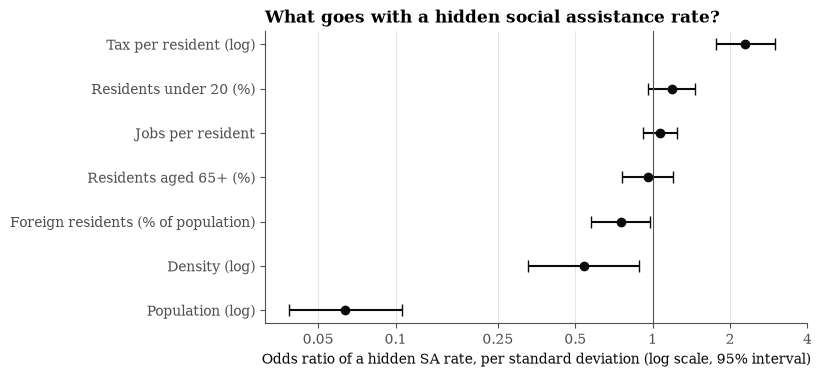

,odds ratio,low,high,p-value
Foreign residents (% of population),0.750,0.576,0.976,0.032
Population (log),0.064,0.039,0.105,0.000
Density (log),0.539,0.327,0.888,0.015
Residents under 20 (%),1.185,0.962,1.461,0.111
Residents aged 65+ (%),0.957,0.762,1.200,0.701
Jobs per resident,1.070,0.918,1.246,0.387
Tax per resident (log),2.293,1.759,2.989,0.000


In [3]:
# Which commune characteristics go with a hidden SA rate? A logit with interpretable
# odds ratios: numeric variables standardised, so each odds ratio is "per standard deviation"
numeric = ["foreign_share", "log_population", "log_density", "share_under20",
           "share_65plus", "jobs_per_capita", "log_tax"]
std = data.copy()
std[numeric] = (std[numeric] - std[numeric].mean()) / std[numeric].std()
logit = smf.logit(f"hidden ~ {' + '.join(numeric)} + C(urban_rural) + C(language)", data=std).fit(
    disp=False, cov_type="cluster", cov_kwds={"groups": pd.factorize(std["canton"])[0]})
_ = (OUT / "logit_hidden.txt").write_text(logit.summary().as_text())

names = {**{v: helpers.LABELS.get(v, v) for v in numeric},
         "log_population": "Population (log)", "log_density": "Density (log)",
         "log_tax": "Tax per resident (log)"}
odds = pd.DataFrame({"odds ratio": np.exp(logit.params), "low": np.exp(logit.conf_int()[0]),
                     "high": np.exp(logit.conf_int()[1]), "p-value": logit.pvalues}).loc[numeric]
odds.index = [names[v] for v in numeric]
odds.to_csv(OUT / "table_odds_ratios.csv")

fig, ax = plt.subplots(figsize=(7, 3.8))
order = odds.sort_values("odds ratio")
ax.errorbar(order["odds ratio"], range(len(order)),
            xerr=[order["odds ratio"] - order["low"], order["high"] - order["odds ratio"]],
            fmt="o", color=helpers.INK["primary"], capsize=4)
ax.axvline(1, color=helpers.INK["secondary"], linewidth=0.8)
ax.set_xscale("log")
ticks = [0.05, 0.1, 0.25, 0.5, 1, 2, 4]
ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
ax.minorticks_off()
ax.set_yticks(range(len(order)), order.index)
ax.set_xlabel("Odds ratio of a hidden SA rate, per standard deviation (log scale, 95% interval)")
ax.set_title("What goes with a hidden social assistance rate?")
ax.grid(axis="x")
helpers.save_figure(fig, OUT / "fig_odds_ratios.png")
plt.show()
odds.round(3)

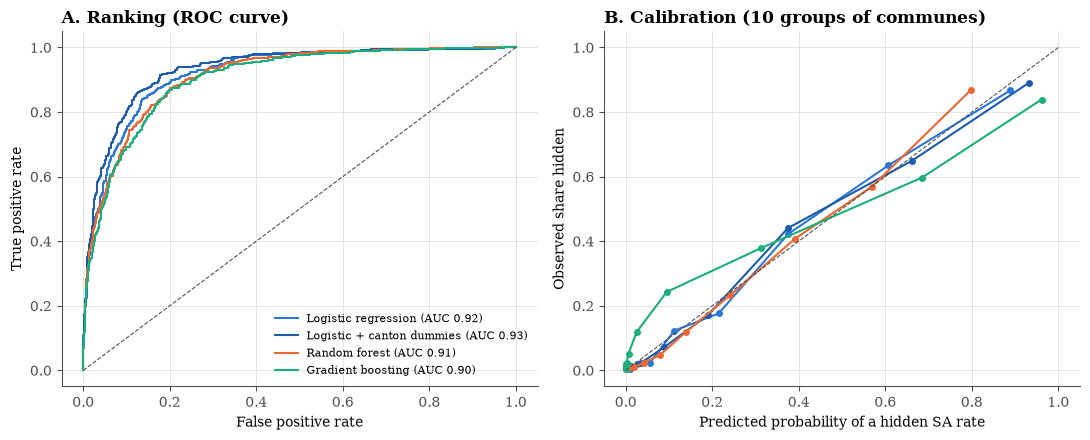

In [4]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve

# Left: can the model rank communes (ROC)? Right: are its probabilities right (calibration)?
shown = ["Logistic regression", "Logistic + canton dummies", "Random forest", "Gradient boosting"]
colours = dict(zip(shown, ["#2a78d6", "#1c5cab", "#eb6834", "#1baf7a"]))
fig, (ax_roc, ax_cal) = plt.subplots(1, 2, figsize=(11, 4.5))
for name in shown:
    fpr, tpr, _ = roc_curve(y, proba[name])
    ax_roc.plot(fpr, tpr, color=colours[name], label=f"{name} (AUC {table_models.loc[name, 'AUC']:.2f})")
    observed, predicted = calibration_curve(y, proba[name], n_bins=10, strategy="quantile")
    ax_cal.plot(predicted, observed, "o-", color=colours[name], markersize=4, label=name)
ax_roc.plot([0, 1], [0, 1], linestyle="--", color=helpers.INK["secondary"], linewidth=0.8)
ax_roc.set(xlabel="False positive rate", ylabel="True positive rate", title="A. Ranking (ROC curve)")
ax_roc.legend(fontsize=8, loc="lower right")
ax_cal.plot([0, 1], [0, 1], linestyle="--", color=helpers.INK["secondary"], linewidth=0.8)
ax_cal.set(xlabel="Predicted probability of a hidden SA rate", ylabel="Observed share hidden",
           title="B. Calibration (10 groups of communes)")
for ax in (ax_roc, ax_cal):
    ax.grid()
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_roc_calibration.png")
plt.show()

In [5]:
# Inverse probability weighting (IPW): give each reported commune the weight
# 1 / P(reported | its characteristics). Communes that look like the hidden ones count more,
# so the weighted reported sample resembles ALL communes. Assumption: once we compare
# communes with the same characteristics, whether SA is reported is unrelated to SA itself.

# Weight model: the classifier with the lowest Brier score (best probabilities, not only ranking)
best = table_models.drop("No model (everyone gets the average)")["Brier score"].idxmin()
p_reported = 1 - pd.Series(proba[best], index=data.index)
reported = data[data["hidden"] == 0].copy()
raw_weights = 1 / p_reported[reported.index]
# Very small probabilities give huge weights: cap them at the 99th percentile
cap = raw_weights.quantile(0.99)
reported["ipw"] = raw_weights.clip(upper=cap)
print(f"Weight model: {best} | weights from {reported['ipw'].min():.2f} to {reported['ipw'].max():.1f} "
      f"(capped at {cap:.1f}) | effective sample size: "
      f"{reported['ipw'].sum() ** 2 / (reported['ipw'] ** 2).sum():.0f} of {len(reported)}")

# Balance check: standardised difference between the reported communes and ALL communes,
# before and after weighting (|difference| < 0.1 is usually called balanced)
balance = {}
for v in numeric:
    sd = data[v].std()
    balance[names[v]] = {
        "Unweighted": (reported[v].mean() - data[v].mean()) / sd,
        "IPW": (np.average(reported[v], weights=reported["ipw"]) - data[v].mean()) / sd}
table_balance = pd.DataFrame(balance).T
table_balance.to_csv(OUT / "table_balance.csv")
display(table_balance.round(3))

# The SA coefficient of notebook 04 (M4), re-estimated with the weights
groups = pd.factorize(reported["canton"])[0]
formula = f"sa_rate ~ {helpers.M4_CONTROLS}"
fits = {
    "Notebook 04 (unweighted)": smf.ols(formula, data=reported),
    "IPW": smf.wls(formula, data=reported, weights=reported["ipw"]),
    "Population-weighted (04 §7)": smf.wls(formula, data=reported, weights=reported["population"]),
    "IPW × population": smf.wls(formula, data=reported, weights=reported["ipw"] * reported["population"]),
}
rows = {}
for name, model in fits.items():
    m = model.fit(cov_type="cluster", cov_kwds={"groups": groups}, use_t=True)
    rows[name] = {"SA: foreign share": helpers.coef_with_stars(m, "foreign_share"),
                  "std. error": f"({m.bse['foreign_share']:.4f})", "N": int(m.nobs)}
table_ipw = pd.DataFrame(rows).T
table_ipw.to_csv(OUT / "table_ipw_sa.csv")
table_ipw

Weight model: Logistic + canton dummies | weights from 1.00 to 6.5 (capped at 6.5) | effective sample size: 1173 of 1625


,Unweighted,IPW
Foreign residents (% of population),0.164,0.038
Population (log),0.313,0.076
Density (log),0.227,0.068
Residents under 20 (%),0.075,0.057
Residents aged 65+ (%),-0.091,-0.039
Jobs per resident,0.058,-0.012
Tax per resident (log),0.019,0.038


,SA: foreign share,std. error,N
Notebook 04 (unweighted),0.0515***,(0.0103),1625
IPW,0.0522***,(0.0096),1625
Population-weighted (04 §7),0.0642***,(0.0178),1625
IPW × population,0.0620***,(0.0173),1625


In [6]:
paper_tables = {
    "table_reported_vs_hidden": table_groups,
    "table_classifiers": table_models,
    "table_odds_ratios": odds,
    "table_balance": table_balance,
    "table_ipw_sa": table_ipw,
}
for name, table in paper_tables.items():
    latex = table.to_latex(escape=True, na_rep="", float_format="%.3f")
    _ = (OUT / f"{name}.tex").write_text(latex, encoding="utf-8")
print("Saved:", len(paper_tables), "tables")

Saved: 5 tables
